# Mixed Poisson equation

This tutorial follows the mixed Poisson demo of
[DOLFINx](https://docs.fenicsproject.org/dolfinx/main/python/demos.html),
with a manufactured solution as in the
[FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/).
We introduce the flux $\sigma = \nabla u$ as a second unknown, so that

$$ \sigma - \nabla u = 0, \qquad \operatorname{div}\sigma = -f \quad \text{in } \Omega = (0,1)^2 . $$

On the left and right sides we prescribe $u = g$, on the top and bottom the normal flux
$\sigma\cdot n = s$.  Testing with $\tau \in H(\mathrm{div})$ and $v \in L^2$ and integrating
$\nabla u \cdot \tau$ by parts gives: find $(\sigma, u)$ with $\sigma \cdot n = s$ on
$\Gamma_N$ such that

$$ \int_\Omega \sigma\cdot\tau + u\,\operatorname{div}\tau \,dx = \int_{\Gamma_D} g\, \tau\cdot n \, ds,
   \qquad
   \int_\Omega v \operatorname{div}\sigma \, dx = -\int_\Omega f v \, dx . $$

The roles are swapped compared to the primal formulation: the Dirichlet data $g$ enters
the right-hand side as a *natural* condition, while the flux condition is *essential* and
has to be imposed on the $H(\mathrm{div})$ space.

We use the manufactured solution $u_e = \cos(\pi x)\sin(2\pi y)$.

## Mixed space and forms

The flux lives in Raviart-Thomas elements of degree $k$ (degree 1 is the lowest order
element, as in FEniCS), the potential in discontinuous Lagrange elements of degree $k-1$.
The product `V * Q` creates the mixed space.

In [1]:
from ngsufl import *
import numpy as np

def solve_mixed(n, k, family="RT"):
    mesh = UnitSquareMesh(n, n)
    V = FunctionSpace(mesh, family, k)
    Q = FunctionSpace(mesh, "DG", k - 1)
    W = V * Q

    x = SpatialCoordinate(mesh)
    u_e = cos(pi * x[0]) * sin(2 * pi * x[1])
    f = -div(grad(u_e))
    nrm = FacetNormal(mesh)

    (sigma, u), (tau, v) = TrialFunctions(W), TestFunctions(W)
    a = (inner(sigma, tau) + u * div(tau) + v * div(sigma)) * dx
    L = -f * v * dx + u_e * dot(tau, nrm) * ds("left|right")

    # essential flux condition sigma.n = grad(u_e).n on top and bottom
    bc = DirichletBC(W.sub(0), grad(u_e), "top|bottom")

    w = Function(W, name="w")
    solve(a == L, w, bc)
    sigma_h, u_h = w.subfunctions
    return mesh, u_e, sigma_h, u_h

mesh, u_e, sigma_h, u_h = solve_mixed(16, 2)
print("ndofs:", sigma_h.function_space().dim(), "+", u_h.function_space().dim())
print("L2 error u    :", errornorm(u_e, u_h))
print("L2 error sigma:", errornorm(grad(u_e), sigma_h))

ndofs: 2624 + 1536
L2 error u    : 0.002988891616961877
L2 error sigma: 0.015748047798803667


The solution has two components, `sigma_h` and `u_h`, which share their data with `w`.
The flux is plotted as its magnitude.

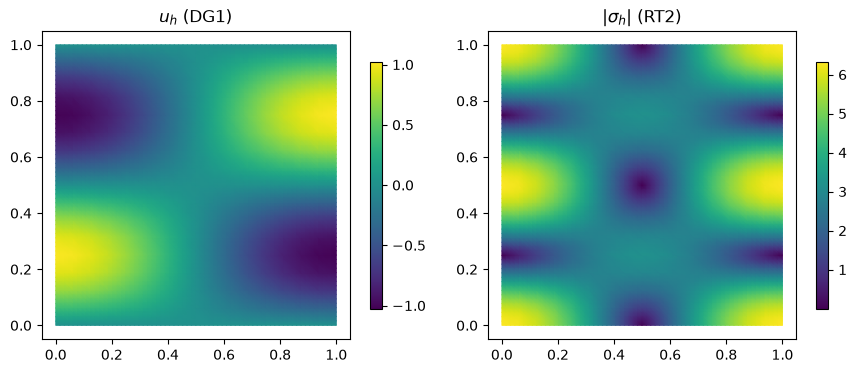

In [2]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
plot(u_h, ax=axs[0])
axs[0].set_title("$u_h$ (DG1)")
plot(sigma_h, ax=axs[1])
axs[1].set_title(r"$|\sigma_h|$ (RT2)")
fig.tight_layout();

## Convergence

For $\mathrm{RT}_k \times \mathrm{DG}_{k-1}$ and $\mathrm{BDM}_k \times \mathrm{DG}_{k-1}$ both
$\|u-u_h\|_{L^2}$ converges with order $k$.  The flux error $\|\sigma-\sigma_h\|_{L^2}$
converges with order $k$ for RT, but with order $k+1$ for BDM, which contains the full
polynomials of degree $k$.

In [3]:
def rates(errs, hs):
    return [np.log(errs[i] / errs[i + 1]) / np.log(hs[i] / hs[i + 1]) for i in range(len(errs) - 1)]

ns = [4, 8, 16, 32]
hs = [1 / n for n in ns]
print(f"{'element':8s} {'':6s}" + "".join(f"{'n=%d' % n:>10s}" for n in ns) + "   rates")
results = {}
for family in ["RT", "BDM"]:
    for k in [1, 2]:
        eu, es = [], []
        for n in ns:
            _, ue, sh, uh = solve_mixed(n, k, family)
            eu.append(errornorm(ue, uh))
            es.append(errornorm(grad(ue), sh))
        results[(family, k)] = (eu, es)
        for name, e in [("u", eu), ("sigma", es)]:
            print(f"{family + str(k):8s} {name:6s}" + "".join(f"{v:10.2e}" for v in e),
                  "  ", " ".join(f"{r:.2f}" for r in rates(e, hs)))

element               n=4       n=8      n=16      n=32   rates
RT1      u       2.07e-01  1.04e-01  5.18e-02  2.59e-02    1.00 1.00 1.00
RT1      sigma   1.43e+00  7.27e-01  3.66e-01  1.83e-01    0.97 0.99 1.00
RT2      u       4.60e-02  1.19e-02  2.99e-03  7.49e-04    1.95 1.99 2.00
RT2      sigma   2.45e-01  6.24e-02  1.57e-02  3.95e-03    1.97 1.99 1.99
BDM1     u       2.01e-01  1.03e-01  5.17e-02  2.59e-02    0.96 0.99 1.00
BDM1     sigma   5.99e-01  1.63e-01  4.16e-02  1.05e-02    1.88 1.96 1.99


BDM2     u       4.58e-02  1.18e-02  2.99e-03  7.49e-04    1.95 1.99 2.00
BDM2     sigma   8.34e-02  1.09e-02  1.38e-03  1.73e-04    2.94 2.98 2.99


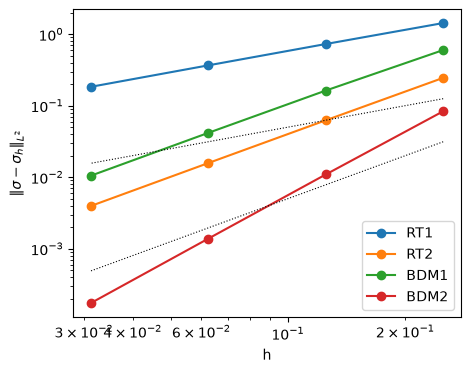

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
for (family, k), (eu, es) in results.items():
    ax.loglog(hs, es, "o-", label=f"{family}{k}")
for k in [1, 2]:
    ax.loglog(hs, [0.5 * h**k for h in hs], "k:", lw=0.8)
ax.set_xlabel("h")
ax.set_ylabel(r"$\|\sigma - \sigma_h\|_{L^2}$")
ax.legend();

## Checking the divergence and the normal continuity

For $\mathrm{RT}_k\times\mathrm{DG}_{k-1}$ the divergence of the flux is the $L^2$ projection
of $-f$ onto $\mathrm{DG}_{k-1}$, so $\operatorname{div}\sigma_h$ must agree with `project(-f, Q)`
up to solver accuracy.  The normal component of an $H(\mathrm{div})$ function is continuous
across element facets; we test it by integrating the squared jump over all interior facets.
Finally the
imposed flux data is matched in the facet moments: the essential condition interpolates
$\sigma\cdot n$, so low order moments of the discrete flux agree with the exact ones.
NGSolve provides $H(\mathrm{div})$ elements of any order, so nothing here is tied to degree 1 or 2.

In [5]:
mesh, u_e, sigma_h, u_h = solve_mixed(16, 2)
Q = u_h.function_space()
nrm = FacetNormal(mesh)
f = -div(grad(u_e))
print("|| div(sigma_h) - P(-f) || :", norm(div(sigma_h) - project(-f, Q)))
print("squared normal jump       :", assemble(inner(jump(sigma_h, nrm), jump(sigma_h, nrm)) * dS))
x = SpatialCoordinate(mesh)
for expr, name in [(sigma_h, "discrete"), (grad(u_e), "exact   ")]:
    print(f"int x sigma.n over top, {name}:", assemble(x[0] * dot(expr, nrm) * ds("top")))

|| div(sigma_h) - P(-f) || : 1.0051291910512689e-13
squared normal jump       : 4.964957277116435e-30
int x sigma.n over top, discrete: -1.2732408616371362
int x sigma.n over top, exact   : -1.2732395447351659
